In [189]:
# Import necessary libraries for data manipulation, financial analysis, HMM, and plotting.
import warnings
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from scipy.optimize import minimize
from pathlib import Path
warnings.filterwarnings("ignore")

In [190]:
# Define tickers, download historical data, and calculate various financial features (returns, volatilities, momentum, correlation, VIX level) for HMM.
TICKERS = ["SPY", "TLT", "GLD", "^VIX"]

prices = yf.download(
    TICKERS,
    start="2005-01-01",
    end="2026-06-30",
    auto_adjust=True,
    progress=False)["Close"]

prices = prices.dropna()
log_returns = np.log(prices / prices.shift(1))
log_returns = log_returns.dropna()

rolling_vol = log_returns["SPY"].rolling(window=63).std() * np.sqrt(252)

rolling_mean = log_returns["SPY"].rolling(window=252).mean()

rolling_var = log_returns["SPY"].rolling(window=252).var()

features = log_returns.copy()

features.columns = [
    "GLD_Return",
    "SPY_Return",
    "TLT_Return",
    "VIX_Return"]

# 20-day rolling volatility
rolling_vol_20 = features.rolling(window=20).std()

rolling_vol_20.columns = ["GLD_Vol20","SPY_Vol20","TLT_Vol20","VIX_Vol20"]

features = pd.concat([features, rolling_vol_20],axis=1)

features = features.dropna()

rolling_vol_63 = (features[["GLD_Return", "SPY_Return", "TLT_Return", "VIX_Return"]].rolling(window=63).std())
rolling_vol_63.columns = ["GLD_Vol63","SPY_Vol63","TLT_Vol63","VIX_Vol63",]

features = pd.concat([features, rolling_vol_63],axis=1)

features = features.dropna()

# 20-Day Momentum
momentum_20 = (prices.pct_change(periods=20))
momentum_20.columns = ["GLD_Mom20","SPY_Mom20","TLT_Mom20","VIX_Mom20"] # Renaming for consistency

momentum_63 = (prices.pct_change(periods=63))
momentum_63.columns = [
    "GLD_Mom63",
    "SPY_Mom63",
    "TLT_Mom63",
    "VIX_Mom63"]

momentum_20 = momentum_20.loc[features.index]
momentum_63 = momentum_63.loc[features.index]

features = pd.concat([features,momentum_20,momentum_63],axis=1)
features = features.dropna()

rolling_corr_spy_tlt = (
    features["SPY_Return"]
    .rolling(window=20)
    .corr(features["TLT_Return"]))

rolling_corr_spy_tlt.name = "SPY_TLT_Corr20"
features = pd.concat([features, rolling_corr_spy_tlt],axis=1)
features = features.dropna()
vix_level = prices["^VIX"].loc[features.index]
features["VIX_Level"] = vix_level

In [191]:
# Define the list of observation features for the HMM and create a copy 'X' from the features DataFrame.
observation_features = [
    "SPY_Return",
    "TLT_Return",

    "SPY_Vol20",
    "SPY_Vol63",

    "TLT_Vol20",
    "TLT_Vol63",

    "SPY_Mom20",
    "SPY_Mom63",

    "TLT_Mom20",
    "TLT_Mom63",

    "SPY_TLT_Corr20",

    "VIX_Level"]

X = features[observation_features].copy()

In [192]:
# Initialize and apply StandardScaler to normalize the observation features, then convert back to DataFrame.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=observation_features)

In [193]:
# Train GaussianHMM models for a range of hidden states, evaluating each with Log-Likelihood, AIC, and BIC.
candidate_states = [2,3,4,5]
model_results = []
trained_models = {}
for n_states in candidate_states:

    model = GaussianHMM(n_components=n_states,covariance_type="full",n_iter=1000,random_state=12)

    model.fit(X_scaled)

    log_likelihood = model.score(X_scaled)

    n_features = X_scaled.shape[1]
    # Number of free parameters: transition matrix, means, and covariance matrices
    n_parameters = ((n_states - 1) + n_states * (n_states - 1) + n_states * n_features
        + n_states * n_features * (n_features + 1) / 2)

    n_samples = X_scaled.shape[0]
    aic = 2 * n_parameters - 2 * log_likelihood
    bic = (np.log(n_samples) * n_parameters - 2 * log_likelihood)

    model_results.append({
        "States": n_states,
        "LogLikelihood": log_likelihood,
        "Parameters": int(n_parameters),
        "AIC": aic,
        "BIC": bic,
        "Converged": model.monitor_.converged})

    trained_models[n_states] = model

In [194]:
# Select the best HMM model (5 states) and predict the hidden states (regimes), then count their occurrences.
best_model = trained_models[5]
hidden_states = best_model.predict(X_scaled)
state_counts = (pd.Series(hidden_states).value_counts().sort_index())

In [195]:
# Define portfolio assets, add predicted regimes to features, and group asset returns by regime.
portfolio_assets = ["SPY_Return", "TLT_Return", "GLD_Return"]

features["Regime"] = hidden_states

regime_returns = {}
for regime in sorted(features["Regime"].unique()):

    regime_data = features.loc[features["Regime"] == regime, portfolio_assets]

    regime_returns[regime] = regime_data.copy()

In [196]:
# Calculate mean returns and covariance matrices for each asset within each identified market regime.
regime_mean_returns = {}

for regime, data in regime_returns.items():

    regime_mean_returns[regime] = data.mean()

# Calculate the covariance matrix for asset returns within each identified market regime
regime_covariance = {}

for regime, data in regime_returns.items():

    regime_covariance[regime] = data.cov()

In [197]:
# Define a function to calculate the negative Sharpe ratio, used as the objective for portfolio optimization.
def negative_sharpe(weights, mean_returns, cov_matrix, risk_free_rate=0):

    # Portfolio expected return
    portfolio_return = np.dot(weights, mean_returns)

    # Portfolio volatility
    portfolio_volatility = np.sqrt(
        np.dot(
            weights.T,
            np.dot(cov_matrix, weights)))

    # Avoid division by zero
    if portfolio_volatility == 0:
        return np.inf

    sharpe_ratio = (portfolio_return - risk_free_rate) / portfolio_volatility
    return -sharpe_ratio

In [198]:
# Determine the number of assets and initialize equal weights as a starting point for optimization.
n_assets = len(portfolio_assets)
initial_weights = np.ones(n_assets) / n_assets

In [199]:
# Define constraints (sum of weights = 1) and bounds (weights between 0 and 1) for portfolio optimization.
constraints = ({"type": "eq", "fun": lambda w: np.sum(w) - 1},)

# Define bounds for the optimization: each asset's weight must be between 0 and 1 (inclusive)
bounds = tuple((0, 1) for _ in range(n_assets))

In [200]:
# Optimize portfolio for each regime by minimizing the negative Sharpe ratio using regime-specific returns and covariance.
optimized_portfolios = {}

for regime in sorted(regime_mean_returns.keys()):
    mean_returns_for_regime = regime_mean_returns[regime]
    cov_matrix_for_regime = regime_covariance[regime]

    result = minimize(
        fun=negative_sharpe,
        x0=initial_weights,
        args=(mean_returns_for_regime, cov_matrix_for_regime),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints)

    optimized_portfolios[regime] = result

In [201]:
# Extract optimal weights from the last optimization result and display them.
optimal_weights = result.x
optimal_weights

array([8.39223964e-01, 8.67361738e-19, 1.60776036e-01])

In [202]:
# Calculate and display the portfolio's expected return, volatility, and Sharpe ratio for the selected regime (Regime 4).
selected_regime = 4 # Since optimal_weights were derived from the last regime (Regime 4)

portfolio_return = np.dot(
    optimal_weights,
    regime_mean_returns[selected_regime])

portfolio_volatility = np.sqrt(
    np.dot(
        optimal_weights.T,
        np.dot(regime_covariance[selected_regime], optimal_weights)))

portfolio_sharpe = (portfolio_return/portfolio_volatility)

In [203]:
def optimize_portfolio(mean_returns,
                       cov_matrix,
                       risk_free_rate=0):

    n_assets = len(mean_returns)

    initial_weights = np.ones(n_assets) / n_assets

    constraints = ({"type": "eq", "fun": lambda w: np.sum(w) - 1},)

    bounds = tuple((0, 1) for _ in range(n_assets))

    result = minimize(
        negative_sharpe,
        initial_weights,
        args=(mean_returns,
              cov_matrix,
              risk_free_rate),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints)

    return result

In [204]:
# Re-run portfolio optimization for each regime using the `optimize_portfolio` function.
optimized_portfolios = {}

for regime in regime_mean_returns.keys():

    result = optimize_portfolio(
        regime_mean_returns[regime],
        regime_covariance[regime]
    )

    optimized_portfolios[regime] = result

In [205]:
# Copy asset returns to `portfolio_returns` DataFrame.
portfolio_returns = features[["SPY_Return","TLT_Return","GLD_Return"]].copy()

In [206]:
# Add the predicted regimes to the `portfolio_returns` DataFrame and shift them by one day to avoid look-ahead bias.
portfolio_returns["Regime"] = hidden_states

portfolio_returns["Regime"] = (
    portfolio_returns["Regime"]
    .shift(1)
)

In [207]:
# Remove any rows with missing data (NaN) after shifting the regimes.
portfolio_returns = portfolio_returns.dropna()

In [208]:
# Convert the 'Regime' column to integer type.
portfolio_returns["Regime"] = (
    portfolio_returns["Regime"]
    .astype(int))

In [209]:
# Extract optimal weights for each regime from optimized portfolios and store them in a DataFrame.
weights = []

for regime, result in optimized_portfolios.items():

    weights.append(
        pd.Series(
            result.x,
            index=portfolio_assets, # Using portfolio_assets for index names
            name=f"Regime {regime}"
        )
    )

weights_df = pd.DataFrame(weights)

In [210]:
# Simulate portfolio performance, applying regime-specific weights and accounting for transaction costs.
strategy_returns = []
portfolio_values = [1.0] # Starting with an initial portfolio value of 1
daily_weights = []
daily_turnover = [] # Initialize daily_turnover list
previous_weights = None
transaction_cost = 0.001 # 10 basis points (0.1%)

# Loop through each day's data to simulate portfolio performance
for date, row in portfolio_returns.iterrows():
    regime = int(row["Regime"])

    weights = weights_df.loc[
        f"Regime {regime}"
    ].values

    # Calculate turnover
    if previous_weights is None:
        turnover = 0
    else:
        turnover = np.sum(np.abs(weights - previous_weights))

    daily_turnover.append(turnover) # Append turnover for each day

    # Calculate cost
    cost = turnover * transaction_cost

    daily_asset_returns = row[portfolio_assets]
    daily_portfolio_return = np.dot(weights, daily_asset_returns)

    # Apply cost to daily return
    daily_return_after_cost = daily_portfolio_return - cost

    strategy_returns.append(daily_return_after_cost)

    latest_portfolio_value = portfolio_values[-1] * (1 + daily_return_after_cost)
    portfolio_values.append(latest_portfolio_value)

    daily_weights.append(weights)
    previous_weights = weights # Update previous_weights for the next iteration

strategy_returns = pd.Series(
    strategy_returns,
    index=portfolio_returns.index,
    name="Strategy_Return")

In [211]:
# Calculate cumulative strategy returns and cumulative asset returns for comparison.
cumulative_strategy_returns = (1 + strategy_returns).cumprod()
cumulative_strategy_returns.name = "Cumulative Strategy Returns"

# Also calculate cumulative returns for individual assets for comparison
cumulative_asset_returns = (1 + portfolio_returns[portfolio_assets]).cumprod()
cumulative_asset_returns.name = "Cumulative Asset Returns"

In [212]:
# Calculate and print the Annualized Return, Annualized Volatility, and Sharpe Ratio of the strategy.

# Assuming 252 trading days in a year
annualization_factor = 252

# Annualized Return
annualized_return = (cumulative_strategy_returns.iloc[-1]**(annualization_factor/len(cumulative_strategy_returns))) - 1

# Annualized Volatility
annualized_volatility = strategy_returns.std() * np.sqrt(annualization_factor)

# Sharpe Ratio
# Assuming risk-free rate is 0 for simplicity, adjust if a specific risk-free rate is available
risk_free_rate = 0
sharpe_ratio = (annualized_return - risk_free_rate) / annualized_volatility

print(f"Annualized Return: {annualized_return:.2%}")
print(f"Annualized Volatility: {annualized_volatility:.2%}")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")

Annualized Return: 13.03%
Annualized Volatility: 13.09%
Sharpe Ratio: 1.00


In [213]:
# Convert the list of portfolio values to a pandas Series, excluding the initial value.
portfolio_values = pd.Series(
    portfolio_values[1:],
    index=portfolio_returns.index,
    name="Portfolio_Value")

In [214]:
# Initialize `previous_weights` to None and define the transaction cost.
previous_weights = None

transaction_cost = 0.001   # 10 basis points (0.10%)

In [215]:
# Calculate turnover based on weight changes from the previous period, or set to 0 if no previous weights exist.
if previous_weights is None:

    turnover = 0

else:

    turnover = np.sum(np.abs(weights - previous_weights))

In [216]:
# Calculate the transaction cost based on turnover and the defined transaction_cost rate.
cost = turnover * transaction_cost

In [217]:
# Convert the list of daily turnover values into a pandas Series.
daily_turnover = pd.Series(
    daily_turnover,
    index=portfolio_returns.index,
    name="Turnover")

In [218]:
# Calculate and print the number of rebalance days and their percentage of total trading days.
rebalance_days = (daily_turnover > 0).sum()

rebalance_percentage = (
    rebalance_days
    /
    len(daily_turnover)
    *100
)

print(f"Rebalance Days : {rebalance_days}")

print(f"Percentage : {rebalance_percentage:.2f}%")

Rebalance Days : 123
Percentage : 2.32%


In [219]:
# Calculate and print the total return of the strategy.
total_return = portfolio_values.iloc[-1] - 1
print(f"Total Return: {total_return:.2%}")

# Calculate and print the Compound Annual Growth Rate (CAGR) of the strategy.
years = (portfolio_values.index[-1] - portfolio_values.index[0]).days / 365.25
cagr = (portfolio_values.iloc[-1]**(1 / years)) - 1
print(f"CAGR: {cagr:.2%}")

# Calculate SPY (S&P 500) returns and its cumulative equity curve for benchmark comparison.
spy_returns = portfolio_returns["SPY_Return"]
spy_equity = (1 + spy_returns).cumprod()

# Calculate and print the annual return of the strategy.
annual_return = strategy_returns.mean() * 252
print(f"Annual Return: {annual_return:.2%}")

# Calculate and print the annual volatility of the strategy.
annual_volatility = strategy_returns.std() * np.sqrt(252)
print(f"Annual Volatility: {annual_volatility:.2%}")

# Calculate and print the Sharpe Ratio for the strategy.
sharpe = annual_return / annual_volatility
print(f"Sharpe Ratio: {sharpe:.2f}")

# Calculate the rolling maximum portfolio value for drawdown calculation.
rolling_max = portfolio_values.cummax()

# Calculate the drawdown (percentage drop from peak equity).
drawdown = (portfolio_values - rolling_max) / rolling_max

# Calculate and print the maximum drawdown of the strategy.
max_drawdown = drawdown.min()
print(f"Maximum Drawdown: {max_drawdown:.2%}")

# Calculate and print the Calmar Ratio for the strategy (CAGR / absolute Max Drawdown).
calmar = cagr / abs(max_drawdown)
print(f"Calmar Ratio: {calmar:.2f}")

# Calculate downside returns, downside volatility, and the Sortino Ratio for the strategy.
downside_returns = strategy_returns[strategy_returns < 0]
downside_vol = downside_returns.std() * np.sqrt(252)
sortino = annual_return / downside_vol
print(f"Sortino Ratio: {sortino:.2f}")

Total Return: 1217.20%
CAGR: 13.01%
Annual Return: 13.11%
Annual Volatility: 13.09%
Sharpe Ratio: 1.00
Maximum Drawdown: -27.30%
Calmar Ratio: 0.48
Sortino Ratio: 1.27


In [220]:
# Create and display a DataFrame summarizing key performance metrics for the strategy.
performance_summary = pd.DataFrame({

    "Metric": [

        "Total Return",

        "CAGR",

        "Annual Return",

        "Annual Volatility",

        "Sharpe Ratio",

        "Sortino Ratio",

        "Maximum Drawdown",

        "Calmar Ratio"

    ],

    "Value": [

        f"{total_return:.2%}",

        f"{cagr:.2%}",

        f"{annual_return:.2%}",

        f"{annual_volatility:.2%}",

        f"{sharpe:.2f}",

        f"{sortino:.2f}",

        f"{max_drawdown:.2%}",

        f"{calmar:.2f}"]})

performance_summary

,Metric,Value
0,Total Return,1217.20%
1,CAGR,13.01%
2,Annual Return,13.11%
3,Annual Volatility,13.09%
4,Sharpe Ratio,1.00
5,Sortino Ratio,1.27
6,Maximum Drawdown,-27.30%
7,Calmar Ratio,0.48


In [221]:
# Define equal weights for assets (SPY, TLT, GLD) and calculate the returns of the equally weighted portfolio.
equal_weights = np.array([1/3, 1/3, 1/3])

equal_returns = (portfolio_returns[portfolio_assets]@ equal_weights)

# Calculate the cumulative equity curve for the equally weighted portfolio.
equal_equity = (1 + equal_returns).cumprod()

In [222]:
# Define weights for a traditional 60/40 portfolio (60% SPY, 40% TLT) and calculate its returns.
weights_6040 = np.array([0.60, 0.40, 0.00])

returns_6040 = (portfolio_returns[portfolio_assets]@ weights_6040)
# Calculate the cumulative equity curve for the 60/40 portfolio.
equity_6040 = (1 + returns_6040).cumprod()

In [223]:
# Define a function to evaluate various performance metrics for a given equity curve and daily returns.
def evaluate_strategy(equity_curve, daily_returns):
    # Calculate number of years for annualized metrics
    years = (equity_curve.index[-1] - equity_curve.index[0]).days / 365.25

    # Total Return
    total_return = equity_curve.iloc[-1] - 1

    # Compound Annual Growth Rate (CAGR)
    cagr = (equity_curve.iloc[-1]** (1 / years)) - 1

    # Annualized Return
    annual_return = daily_returns.mean() * 252

    # Annualized Volatility
    annual_vol = daily_returns.std() * np.sqrt(252)

    # Sharpe Ratio (assuming 0 risk-free rate)
    sharpe = annual_return / annual_vol

    # Downside returns for Sortino Ratio calculation
    downside = daily_returns[daily_returns < 0]

    # Sortino Ratio
    sortino = annual_return / (downside.std() * np.sqrt(252))

    # Calculate Max Drawdown
    rolling_max = equity_curve.cummax()
    drawdown = (equity_curve - rolling_max) / rolling_max
    max_dd = drawdown.min()

    # Calmar Ratio
    calmar = cagr / abs(max_dd)

    return {
        "Total Return": total_return,
        "CAGR": cagr,
        "Volatility": annual_vol,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max Drawdown": max_dd,
        "Calmar": calmar
    }

In [224]:
# Create and display a DataFrame comparing key performance metrics for all strategies and benchmarks.
results = pd.DataFrame({

    "Regime Strategy":
        evaluate_strategy(
            portfolio_values,
            strategy_returns),

    "Buy & Hold SPY":
        evaluate_strategy(
            spy_equity,
            spy_returns),

    "Equal Weight":
        evaluate_strategy(
            equal_equity,
            equal_returns),

    "60/40":
        evaluate_strategy(
            equity_6040,
            returns_6040)}).T

results

,Total Return,CAGR,Volatility,Sharpe,Sortino,Max Drawdown,Calmar
Regime Strategy,12.172019,0.130102,0.130935,1.001467,1.267324,-0.273039,0.476496
Buy & Hold SPY,5.190854,0.090339,0.190871,0.549688,0.654380,-0.595760,0.151637
Equal Weight,3.762036,0.076850,0.098731,0.800672,1.081674,-0.239852,0.320407
60/40,3.204652,0.070509,0.111760,0.666660,0.845006,-0.346056,0.203752


## ***"Performance Attribution"***

In [225]:
# Create an 'analysis' DataFrame to store regime, strategy returns, and portfolio values.
analysis = pd.DataFrame(index=portfolio_returns.index)
analysis["Regime"] = portfolio_returns["Regime"]
analysis["Strategy_Return"] = strategy_returns
analysis["Portfolio_Value"] = portfolio_values

In [226]:
# Group the 'analysis' DataFrame by regime and aggregate strategy return statistics.
regime_stats = (analysis.groupby("Regime").agg({"Strategy_Return":["count","mean","std","min","max"]}))
regime_stats

Strategy_Return                                        
                 count      mean       std       min       max
Regime                                                        
0                 1317  0.000408  0.009578 -0.050536  0.037675
1                  678  0.000651  0.013053 -0.049491  0.053128
2                 1208  0.000496  0.004325 -0.014318  0.016740
3                  180  0.001604  0.015620 -0.043425  0.050270
4                 1920  0.000464  0.005504 -0.039915  0.019363

In [227]:
# Create a summary DataFrame for regime performance, including days, annual return, and annual volatility.
regime_summary = pd.DataFrame()
regime_summary["Days"] = (analysis.groupby("Regime").size())
regime_summary["Annual Return"] = (analysis.groupby("Regime")["Strategy_Return"].mean()*252)
regime_summary["Annual Volatility"] = (analysis.groupby("Regime")["Strategy_Return"].std()*np.sqrt(252))

In [228]:
# Calculate the Sharpe Ratio for each regime and add it to the regime_summary DataFrame.
regime_summary["Sharpe"] = (regime_summary["Annual Return"]/regime_summary["Annual Volatility"])

In [229]:
# Display the regime_summary DataFrame, which includes performance metrics per regime.
regime_summary

,Days,Annual Return,Annual Volatility,Sharpe
Regime,,,,
0,1317,0.102938,0.152044,0.677029
1,678,0.164099,0.207215,0.791928
2,1208,0.125070,0.068651,1.821809
3,180,0.404257,0.247952,1.630381
4,1920,0.117025,0.087375,1.339345


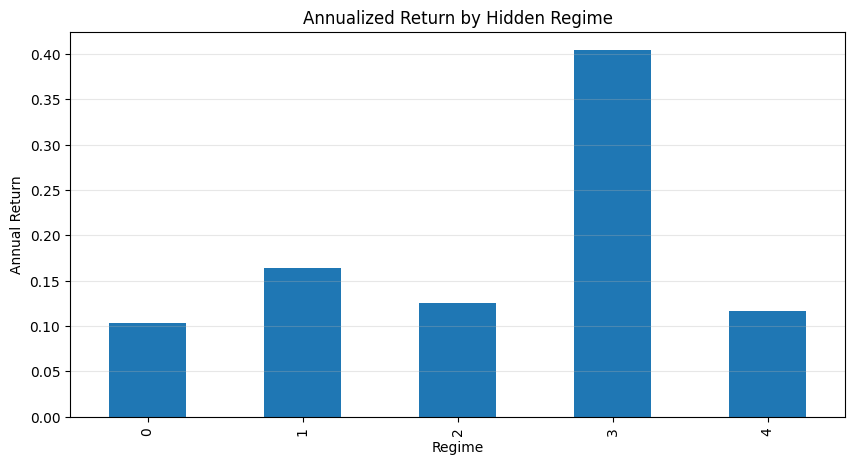

In [230]:
# Plot the annualized return for each hidden regime using a bar chart.
plt.figure(figsize=(10,5))
regime_summary["Annual Return"].plot(kind="bar")
plt.title("Annualized Return by Hidden Regime")
plt.ylabel("Annual Return")
plt.grid(axis="y",alpha=0.3)
plt.show()

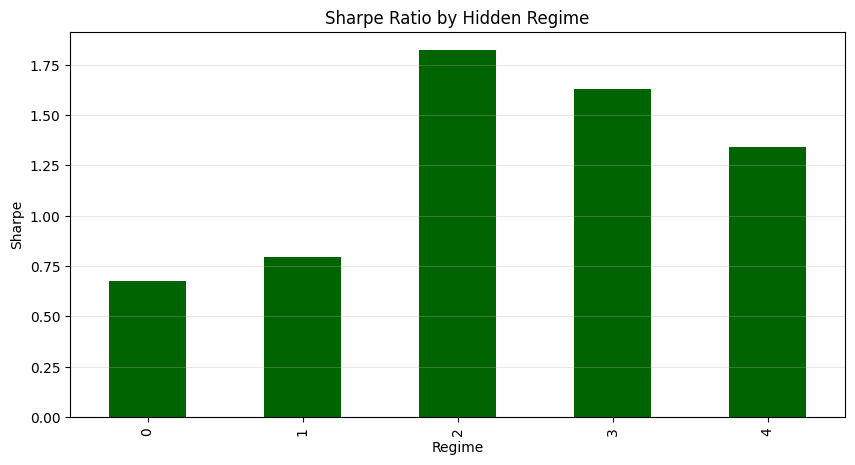

In [231]:
# Plot the Sharpe Ratio for each hidden regime using a bar chart.
plt.figure(figsize=(10,5))
regime_summary["Sharpe"].plot(kind="bar",color="darkgreen")
plt.title("Sharpe Ratio by Hidden Regime")
plt.ylabel("Sharpe")
plt.grid(axis="y",alpha=0.3)
plt.show()

## ***"Drawdown Attribution"***

In [232]:
# Calculate the rolling maximum of the portfolio value and the subsequent drawdown.
analysis["Rolling_Max"] = analysis["Portfolio_Value"].cummax()
analysis["Drawdown"] = (analysis["Portfolio_Value"] - analysis["Rolling_Max"]) / analysis["Rolling_Max"]

In [233]:
# Display the first few rows of the 'analysis' DataFrame, now including Rolling_Max and Drawdown.
analysis.head()

,Regime,Strategy_Return,Portfolio_Value,Rolling_Max,Drawdown
Date,,,,,
2005-05-31,4,-0.006276,0.993724,0.993724,0.000000
2005-06-01,4,0.006670,1.000352,1.000352,0.000000
2005-06-02,4,0.004000,1.004353,1.004353,0.000000
2005-06-03,4,-0.003983,1.000353,1.004353,-0.003983
2005-06-06,4,0.000409,1.000762,1.004353,-0.003575


In [234]:
# Group the 'analysis' DataFrame by regime to summarize drawdown statistics.
drawdown_summary = (analysis.groupby("Regime")["Drawdown"].agg([
        "mean",
        "min",
        "max"]))
drawdown_summary.columns = ["Average Drawdown", "Maximum Drawdown", "Best Level"]
drawdown_summary

,Average Drawdown,Maximum Drawdown,Best Level
Regime,,,
0,-0.036061,-0.201195,0.0
1,-0.109099,-0.273039,0.0
2,-0.028917,-0.103501,0.0
3,-0.066909,-0.171419,0.0
4,-0.016469,-0.130722,0.0


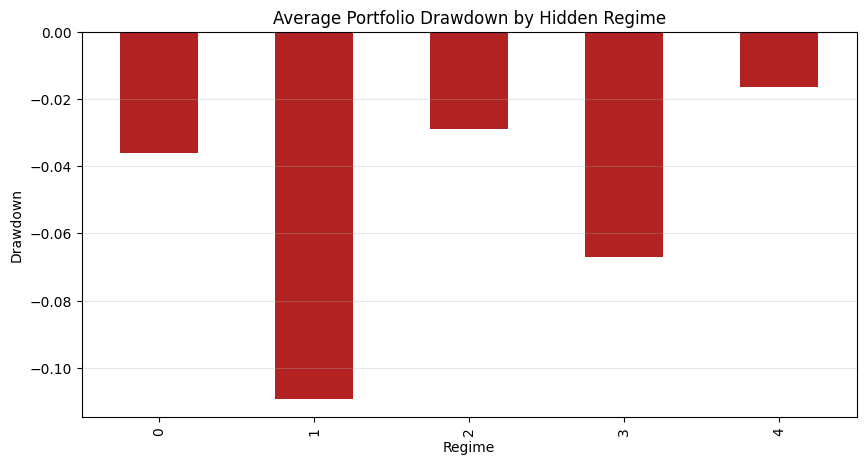

In [235]:
# Plot the average portfolio drawdown for each hidden regime using a bar chart.
plt.figure(figsize=(10,5))
drawdown_summary["Average Drawdown"].plot(kind="bar", color="firebrick")
plt.title("Average Portfolio Drawdown by Hidden Regime")
plt.ylabel("Drawdown")
plt.grid(axis="y", alpha=0.3)
plt.show()

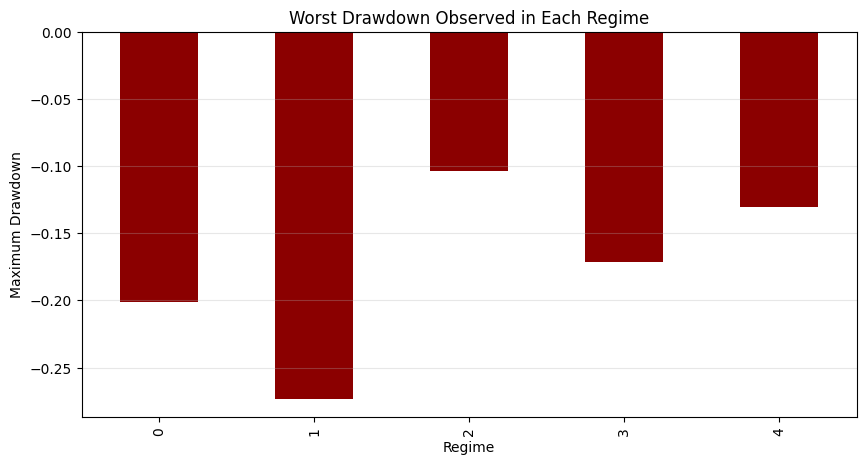

In [236]:
# Plot the maximum drawdown observed in each regime using a bar chart.
plt.figure(figsize=(10,5))
drawdown_summary["Maximum Drawdown"].plot(kind="bar", color="darkred")
plt.title("Worst Drawdown Observed in Each Regime")
plt.ylabel("Maximum Drawdown")
plt.grid(axis="y", alpha=0.3)
plt.show()

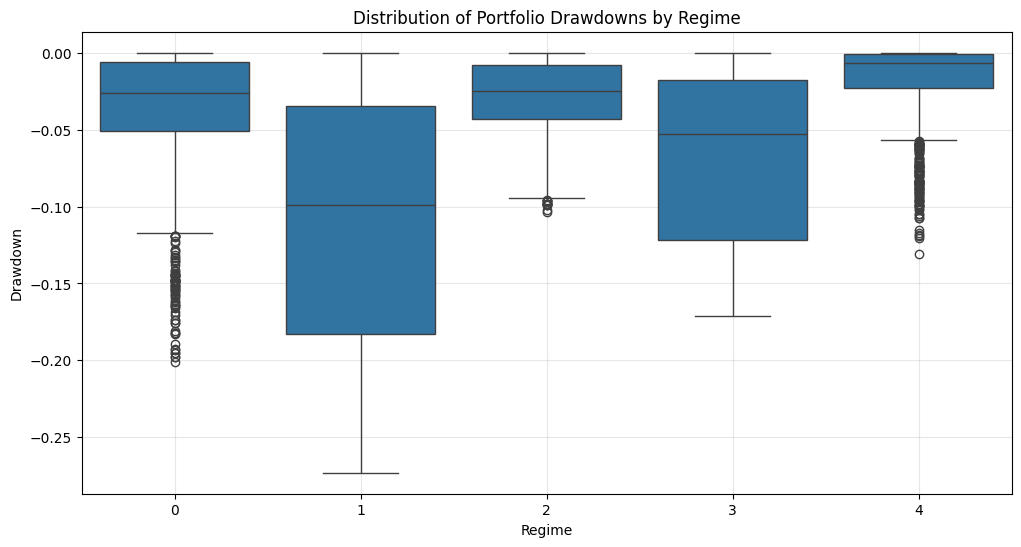

In [237]:
# Create a box plot to visualize the distribution of portfolio drawdowns for each regime.
plt.figure(figsize=(12,6))
sns.boxplot(data=analysis, x="Regime", y="Drawdown")
plt.title("Distribution of Portfolio Drawdowns by Regime")
plt.grid(alpha=0.3)
plt.show()

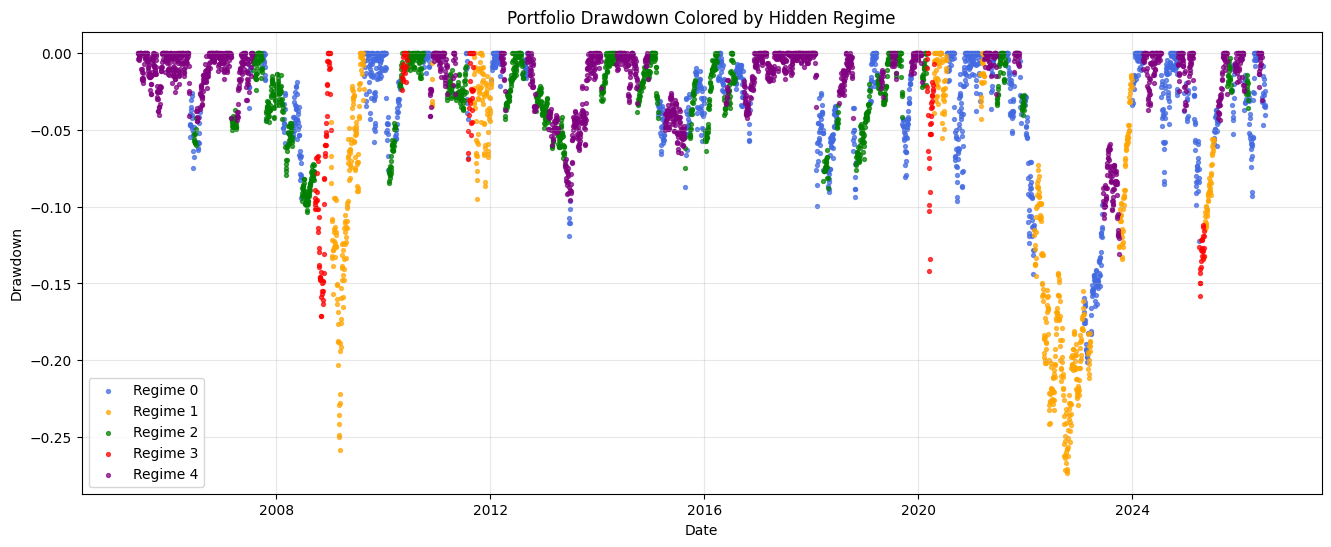

In [238]:
# Visualize portfolio drawdown over time, colored by the identified hidden market regimes.
plt.figure(figsize=(16,6))

colors = {
    0: "royalblue",
    1: "orange",
    2: "green",
    3: "red",
    4: "purple"}

for regime in sorted(analysis["Regime"].unique()):

    mask = analysis["Regime"] == regime

    plt.scatter(
        analysis.index[mask],
        analysis.loc[mask, "Drawdown"],
        s=8,
        color=colors[regime],
        label=f"Regime {regime}",
        alpha=0.7)

plt.title("Portfolio Drawdown Colored by Hidden Regime")
plt.ylabel("Drawdown")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## ***"Rolling Performance Analysis"***

In [239]:
# Calculate the rolling 1-year (252-day) return of the strategy.
rolling_return = ((1 + strategy_returns).rolling(252).apply(np.prod, raw=True) - 1)

In [240]:
# Calculate the rolling annualized volatility of the strategy over a 252-day window.
rolling_vol = (strategy_returns.rolling(252).std()* np.sqrt(252))

In [241]:
# Calculate the rolling Sharpe Ratio by dividing rolling return by rolling volatility.
rolling_sharpe = (rolling_return/rolling_vol)

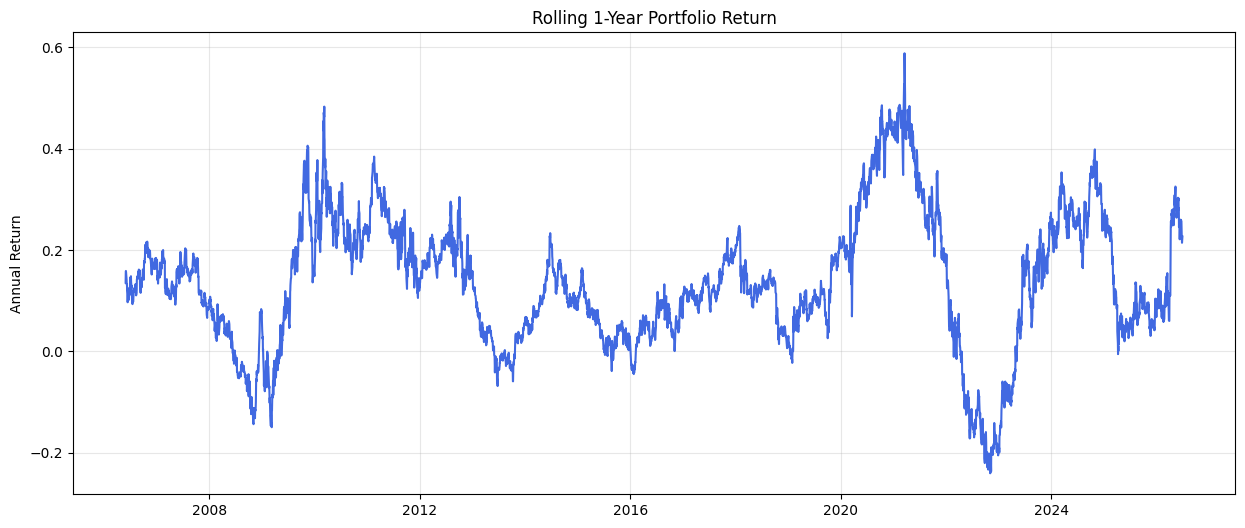

In [242]:
# Plot the rolling 1-year portfolio return over time.
plt.figure(figsize=(15,6))
plt.plot(rolling_return,color="royalblue")
plt.title("Rolling 1-Year Portfolio Return")
plt.ylabel("Annual Return")
plt.grid(alpha=0.3)
plt.show()

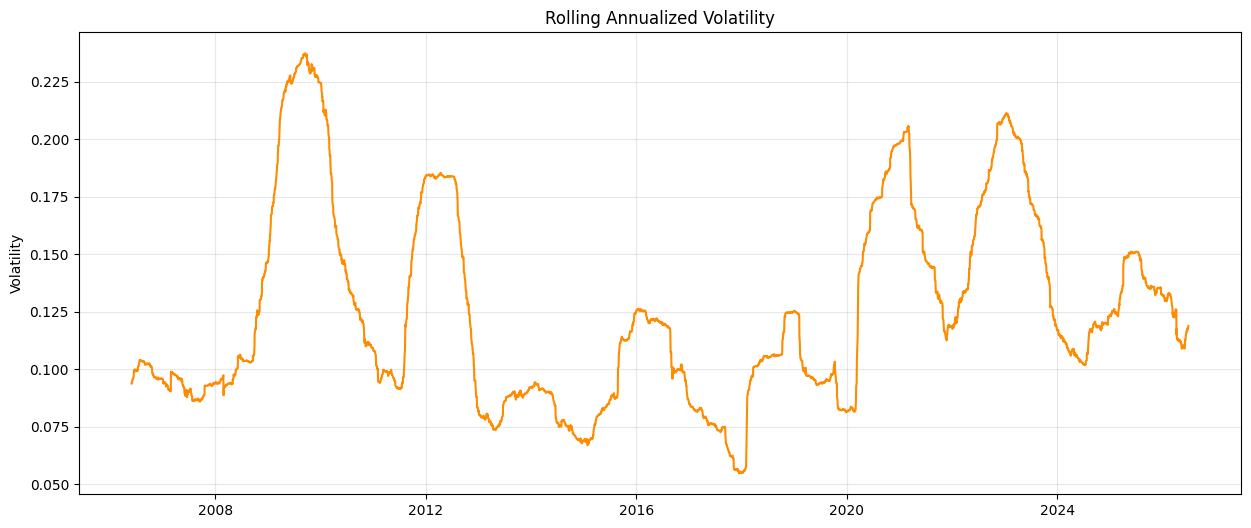

In [243]:
# Plot the rolling annualized volatility over time.
plt.figure(figsize=(15,6))
plt.plot(rolling_vol, color="darkorange")
plt.title("Rolling Annualized Volatility")
plt.ylabel("Volatility")
plt.grid(alpha=0.3)
plt.show()

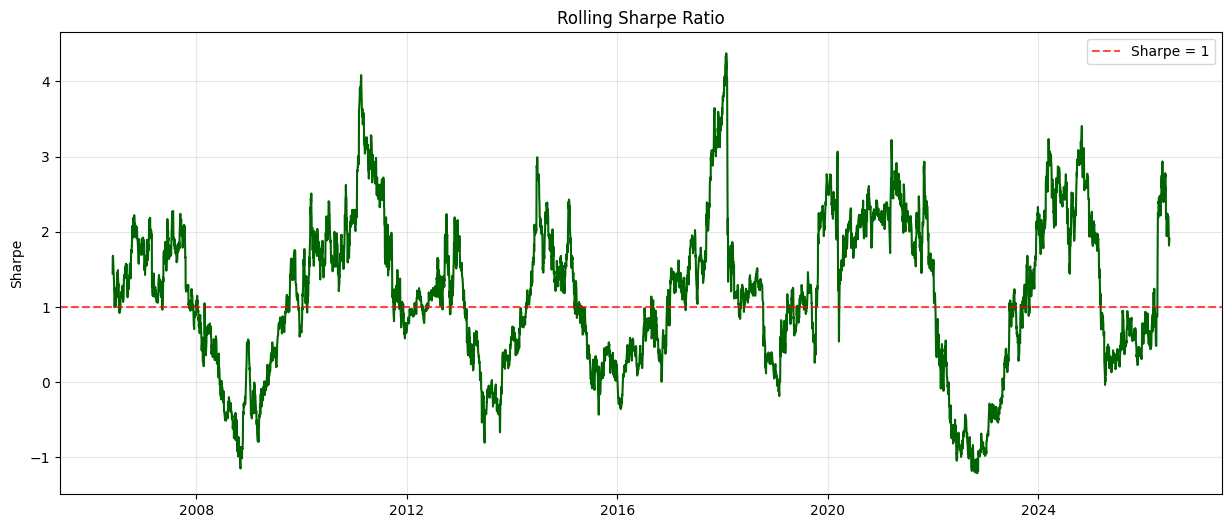

In [244]:
# Plot the rolling Sharpe Ratio over time, with a horizontal line indicating a Sharpe Ratio of 1.
plt.figure(figsize=(15,6))
plt.plot(rolling_sharpe, color="darkgreen")
plt.axhline(1, linestyle="--", color="red", alpha=0.7, label="Sharpe = 1")
plt.title("Rolling Sharpe Ratio")
plt.ylabel("Sharpe")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [245]:
# Create a summary DataFrame of descriptive statistics for rolling return, volatility, and Sharpe ratio.
rolling_summary = pd.DataFrame({

    "Rolling Return": rolling_return.describe(),

    "Rolling Volatility": rolling_vol.describe(),

    "Rolling Sharpe": rolling_sharpe.describe()})

rolling_summary

,Rolling Return,Rolling Volatility,Rolling Sharpe
count,5052.000000,5052.000000,5052.000000
mean,0.135678,0.124834,1.175038
std,0.130217,0.042477,0.997493
min,-0.240510,0.054807,-1.210035
25%,0.052692,0.093263,0.453235
50%,0.125985,0.113680,1.176064
75%,0.217400,0.150459,1.913472
max,0.588381,0.237348,4.374414


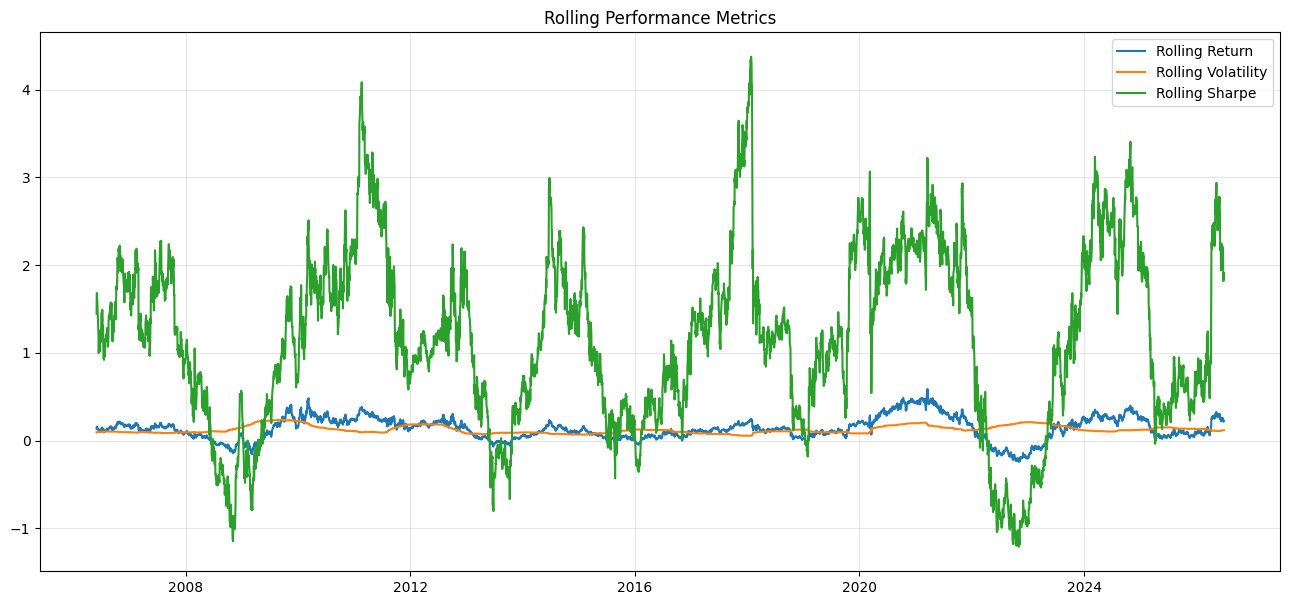

In [246]:
# Plot all three rolling performance metrics (return, volatility, and Sharpe ratio) on a single chart for comparison.
fig, ax = plt.subplots(figsize=(16,7))

ax.plot(
    rolling_return,
    label="Rolling Return"
)

ax.plot(
    rolling_vol,
    label="Rolling Volatility"
)

ax.plot(
    rolling_sharpe,
    label="Rolling Sharpe"
)

plt.legend()

plt.title("Rolling Performance Metrics")

plt.grid(alpha=0.3)

plt.show()

## ***"Regime Transition & Stability Analysis"***

In [247]:
# Calculate and print the total number of times the hidden market regime changes.
regime_changes = (analysis["Regime"]!=analysis["Regime"].shift(1)).sum()
print("Total Regime Changes:", regime_changes)

Total Regime Changes: 124


In [248]:
# Calculate and print the frequency of regime switches as a percentage of total trading days.
switch_percentage = (regime_changes/len(analysis)) * 100
print(f"Switch Frequency: {switch_percentage:.2f}%")

Switch Frequency: 2.34%


In [249]:
# Identify continuous runs of each regime and calculate their durations.
regime_runs = (analysis["Regime"]!=analysis["Regime"].shift()).cumsum()
durations = (analysis.groupby(regime_runs).size())
run_regimes = (analysis.groupby(regime_runs)["Regime"].first())
duration_df = pd.DataFrame({

    "Regime": run_regimes,

    "Duration": durations})

duration_df.head()

,Regime,Duration
Regime,,
1,4,244
2,0,20
3,2,11
4,4,7
5,0,9


In [250]:
duration_df.index.name = None # Remove the index name to avoid ambiguity

duration_summary = (duration_df.groupby("Regime")["Duration"].agg(
        [
        "count",
        "mean",
        "median",
        "max"]))

duration_summary.columns = [

    "Occurrences",

    "Average Duration",

    "Median Duration",

    "Longest Duration"]

duration_summary

,Occurrences,Average Duration,Median Duration,Longest Duration
Regime,,,,
0,41,32.121951,21.0,159
1,9,75.333333,60.0,234
2,34,35.529412,31.5,86
3,5,36.000000,26.0,75
4,35,54.857143,26.0,309


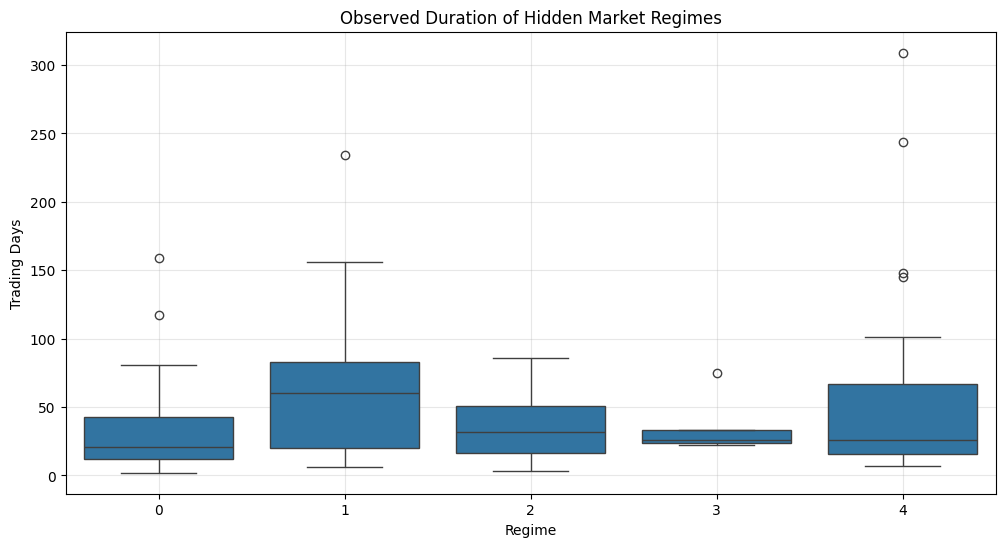

In [251]:
# Create a box plot to visualize the distribution of observed durations for each hidden market regime.
plt.figure(figsize=(12,6))

sns.boxplot(
    data=duration_df,
    x="Regime",
    y="Duration"
)

plt.title("Observed Duration of Hidden Market Regimes")

plt.ylabel("Trading Days")

plt.grid(alpha=0.3)

plt.show()

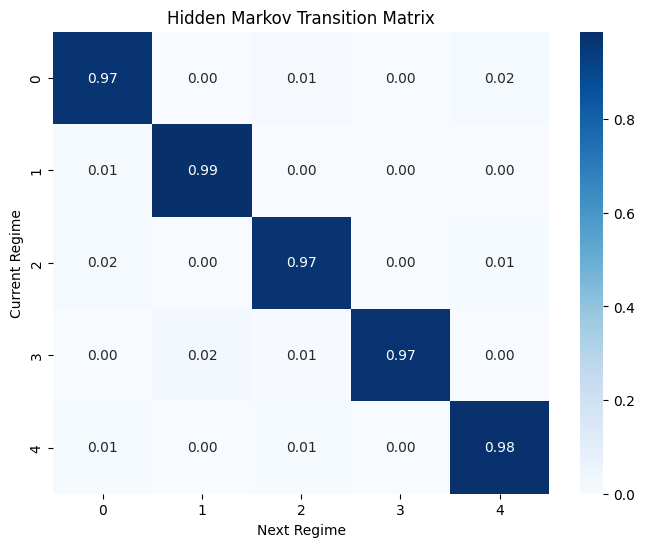

In [252]:
transition_matrix = best_model.transmat_

plt.figure(figsize=(8,6))

sns.heatmap(

    transition_matrix,

    annot=True,

    cmap="Blues",

    fmt=".2f"

)

plt.title("Hidden Markov Transition Matrix")

plt.xlabel("Next Regime")

plt.ylabel("Current Regime")

plt.show()

In [253]:
# Calculate a cross-tabulation of regime transitions to count how often one regime follows another.
transition_counts = pd.crosstab(

    analysis["Regime"],

    analysis["Regime"].shift(-1)

)

transition_counts

Regime,0.0,1.0,2.0,3.0,4.0
Regime,,,,,
0,1276,3,15,2,20
1,7,669,0,0,2
2,19,0,1174,3,12
3,0,4,1,175,0
4,15,2,18,0,1885


In [254]:
# Create a copy of the transition counts and set diagonal elements to zero to focus on actual regime changes.
transition_counts_no_diag = transition_counts.copy()

for i in transition_counts_no_diag.index:
    transition_counts_no_diag.loc[i, i] = 0

transition_counts_no_diag

Regime,0.0,1.0,2.0,3.0,4.0
Regime,,,,,
0,0,3,15,2,20
1,7,0,0,0,2
2,19,0,0,3,12
3,0,4,1,0,0
4,15,2,18,0,0


In [255]:
# Display the top 10 most frequent regime transitions (excluding self-transitions).
transition_counts_no_diag.stack().sort_values(ascending=False).head(10)

,,0
Regime,Regime,
0,4.0,20
2,0.0,19
4,2.0,18
0,2.0,15
4,0.0,15
2,4.0,12
1,0.0,7
3,1.0,4
0,1.0,3


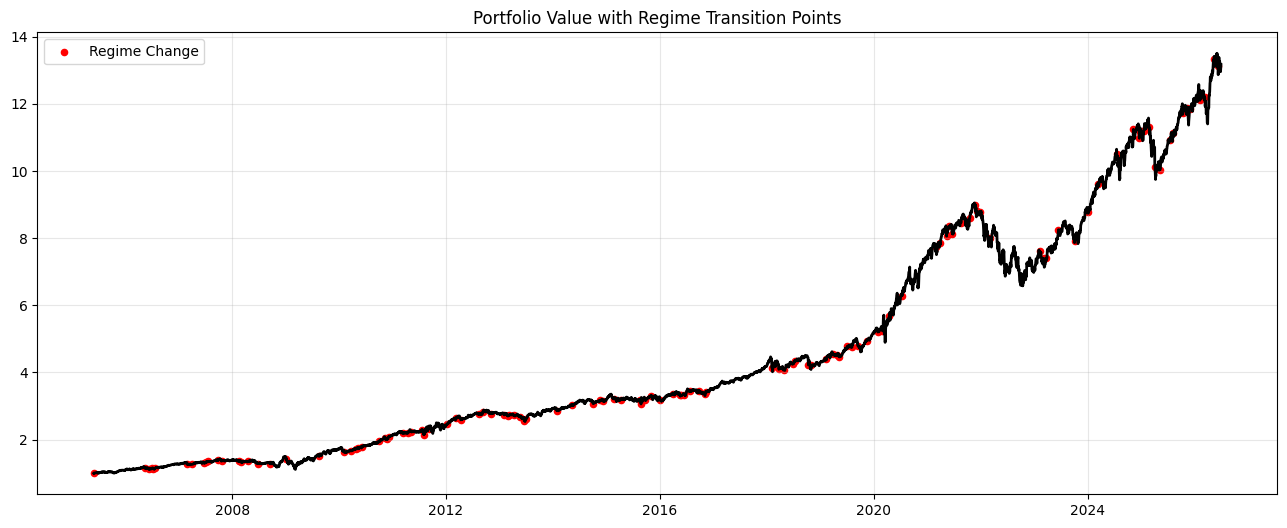

In [256]:
plt.figure(figsize=(16,6))

plt.plot(
    analysis["Portfolio_Value"],
    color="black",
    lw=2
)

switches = (
    analysis["Regime"]
    !=
    analysis["Regime"].shift()
)

plt.scatter(

    analysis.index[switches],

    analysis["Portfolio_Value"][switches],

    color="red",

    s=20,

    label="Regime Change"

)

plt.title("Portfolio Value with Regime Transition Points")

plt.legend()

plt.grid(alpha=0.3)

plt.show()